# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- Name: Anisa Sachdev
- Student ID: 023-24-0222
- Section: G
- Dataset: Telco Customer Churn (Kaggle)


---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.

---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [ ]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("telco-churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df = df.drop("customerID", axis=1)


In [ ]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset shape:", df.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts())
print("Testing target distribution:")
print(y_test.value_counts())

Dataset shape: (7043, 31)
Training features: (5634, 30)
Testing features: (1409, 30)
Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64
Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [ ]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

def metrics(y_true, y_pred):
    return dict(Accuracy=accuracy_score(y_true, y_pred), Precision=precision_score(y_true, y_pred),
                Recall=recall_score(y_true, y_pred), F1=f1_score(y_true, y_pred))

# UNSCALED linear SVM. max_iter is capped (otherwise the solver can run for a very long time on raw features)
with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel='linear', random_state=42, max_iter=200000)
    svm_raw.fit(X_train, y_train)
    t_raw = time.time() - t0
m_raw = metrics(y_test, svm_raw.predict(X_test))
print("UNSCALED ->", {k: round(v, 4) for k, v in m_raw.items()}, "| train time: %.2fs" % t_raw)
print("Warnings:", [str(w.message)[:90] for w in w_raw])
print("Features with largest range:\n", (X_train.max() - X_train.min()).sort_values(ascending=False).head(3))

UNSCALED -> {'Accuracy': 0.4556, 'Precision': 0.1915, 'Recall': 0.3262, 'F1': 0.2413} | train time: 5.39s
Warnings: ['Solver terminated early (max_iter=200000).  Consider pre-processing your data with Standar']
Features with largest range:
 TotalCharges      8665.95
MonthlyCharges     100.35
tenure              72.00
dtype: float64


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit on TRAIN only
X_test_s  = scaler.transform(X_test)        # transform only on TEST

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_s = SVC(kernel='linear', random_state=42)
    svm_s.fit(X_train_s, y_train)
    t_s = time.time() - t0
m_s = metrics(y_test, svm_s.predict(X_test_s))
print("SCALED   ->", {k: round(v, 4) for k, v in m_s.items()}, "| train time: %.2fs" % t_s)
print("Warnings:", [str(w.message)[:90] for w in w_s])

import pandas as pd
pd.DataFrame({"Unscaled": {**m_raw, "Train time (s)": t_raw, "Conv. warning": len(w_raw) > 0},
              "Scaled":   {**m_s,   "Train time (s)": t_s,   "Conv. warning": len(w_s) > 0}}).T.round(4)

SCALED   -> {'Accuracy': 0.7892, 'Precision': 0.6207, 'Recall': 0.5294, 'F1': 0.5714} | train time: 1.16s
Warnings: []


,Accuracy,Precision,Recall,F1,Train time (s),Conv. warning
Unscaled,0.455642,0.191523,0.326203,0.241345,5.388077,True
Scaled,0.789212,0.62069,0.529412,0.571429,1.155881,False


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

**Answer:** Unscaled model got accuracy 0.456 and F1 0.241, it took 5.19 s and gave a convergence warning. Scaled model got accuracy 0.789 and F1 0.571 in 1.23 s with no warning. The unscaled accuracy is even lower than just predicting everyone as No churn (about 0.735).


(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

**Answer:** SVM uses distances to find the margin. TotalCharges goes up to about 8666 while the 0/1 columns only change by 1, so the big columns control everything and the small columns hardly matter. The solver also struggles to converge because the feature ranges are so different.


(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

**Answer:** I will use the scaled version for everything after this, because it gives much better results (F1 0.571 vs 0.241). I fit the scaler on train only so there is no data leakage.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [ ]:
kernels = ['linear', 'rbf', 'poly']
models, rows, times = {}, [], {}
for k in kernels:
    t0 = time.time()
    m = SVC(kernel=k, random_state=42).fit(X_train_s, y_train)
    times[k] = time.time() - t0
    models[k] = m
    rows.append({"Kernel": k, **metrics(y_test, m.predict(X_test_s)),
                 "Support Vectors": m.support_.shape[0], "SV per class": list(m.n_support_),
                 "Train time (s)": times[k]})

In [ ]:
kernel_df = pd.DataFrame(rows).set_index("Kernel")
kernel_df.round(4)

,Accuracy,Precision,Recall,F1,Support Vectors,SV per class,Train time (s)
Kernel,,,,,,,
linear,0.7892,0.6207,0.5294,0.5714,2569,"[1287, 1282]",1.1604
rbf,0.7928,0.6444,0.4893,0.5562,2661,"[1432, 1229]",0.7344
poly,0.7892,0.6421,0.4652,0.5395,2739,"[1485, 1254]",0.6678


Best kernel on F1: linear


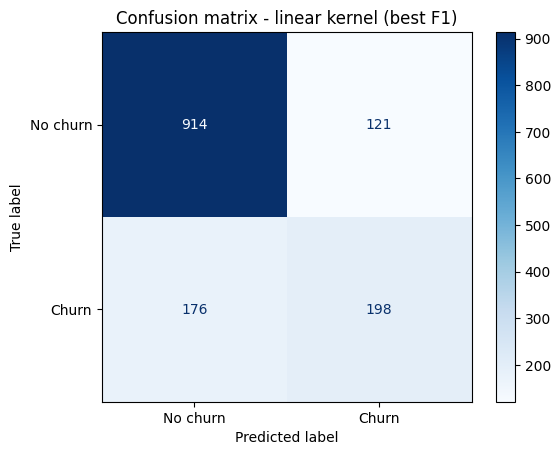

In [ ]:
best_kernel = kernel_df["F1"].idxmax()
print("Best kernel on F1:", best_kernel)
ConfusionMatrixDisplay.from_estimator(models[best_kernel], X_test_s, y_test,
                                      display_labels=["No churn", "Churn"], cmap="Blues")
plt.title(f"Confusion matrix - {best_kernel} kernel (best F1)")
plt.show()

**Interpretation:** The linear model got 198 churners right and missed about 176 (recall 0.529). It wrongly flagged about 121 loyal customers (precision 0.621). Many churners are missed, which is why we try class weights in Part 5.

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

**Answer:** Linear kernel gave the best F1 (0.571). RBF got 0.556 and poly got 0.540. It is a little surprising because RBF is supposed to be more powerful, but the difference is small and the data is mostly 0/1 columns, so a linear boundary works fine.


(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

**Answer:** Poly used the most support vectors (2739), then RBF (2661) and linear (2569). That is almost half of the 5634 training rows, so the classes overlap a lot and the boundary is not simple.


(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

**Answer:** I will take RBF forward for tuning. All three kernels are close (F1 between 0.540 and 0.571) and RBF has the best accuracy (0.793) and precision (0.644). Also RBF has gamma that we can tune, and it was only using default values here.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d  = pca.transform(X_test_s)
print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 PCs): %.4f" % pca.explained_variance_ratio_.sum())

Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 PCs): 0.4523


In [ ]:
C_values = [0.01, 1, 100]
svm_2d = {}
for c in C_values:
    svm_2d[c] = SVC(kernel='rbf', C=c, gamma='scale', random_state=42).fit(X_train_2d, y_train)
    print(f"C={c:<6} support vectors = {svm_2d[c].support_.shape[0]:>4}  | "
          f"train acc = {svm_2d[c].score(X_train_2d, y_train):.4f} | test acc = {svm_2d[c].score(X_test_2d, y_test):.4f}")

C=0.01   support vectors = 2997  | train acc = 0.7346 | test acc = 0.7346


C=1      support vectors = 2659  | train acc = 0.7792 | test acc = 0.7786


C=100    support vectors = 2631  | train acc = 0.7813 | test acc = 0.7793


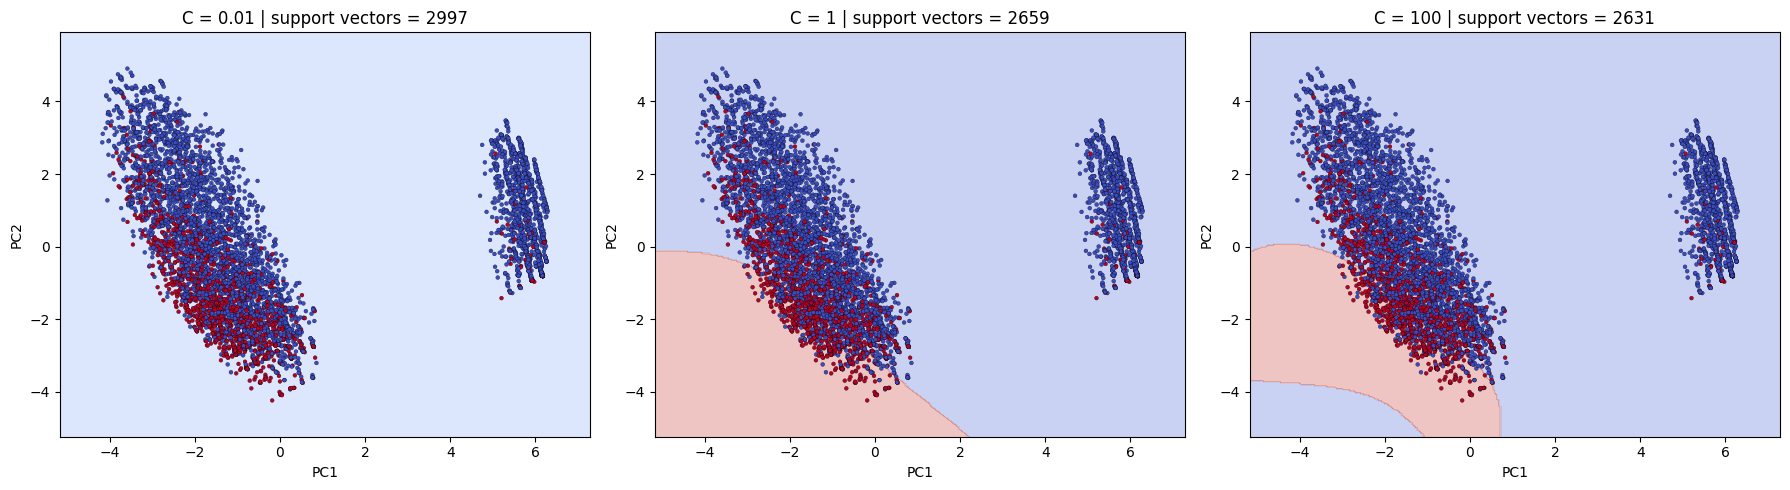

In [ ]:
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, C_values):
    Z = svm_2d[c].predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm", s=8, edgecolor="k", linewidth=0.2)
    ax.set_title(f"C = {c} | support vectors = {svm_2d[c].support_.shape[0]}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Interpretation:** At C=0.01 everything is predicted as No churn. At C=1 and C=100 there is a curved Churn region at the bottom left. The classes overlap a lot, so no C separates them well.

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

**Answer:** When C is 0.01 there is no boundary, the whole plot is predicted as No churn. At C=1 a smooth curved boundary appears at the bottom left. At C=100 the boundary is a bit bigger and more curved. PCA with 2 components only keeps 45.2% of the variance (0.3325 + 0.1198).


(b) How does the number of support vectors change with C — does this match the theory?

**Answer:** Support vectors went down as C went up: 2997, 2659, 2631. This matches the theory, because a small C allows many points inside the margin and a large C punishes them. From C=1 to C=100 it barely changed because the classes overlap too much.


(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

**Answer:** C=0.01 is underfitting because it predicts only No churn (accuracy 0.7346, same as the majority class). C=100 is closest to overfitting because it has the most flexible boundary, but it is not bad (train 0.7813, test 0.7793). C=1 looks the most reasonable.


(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

**Answer:** Because 2 components keep less than half of the information (45.2%), so the plot hides a lot. Points that overlap here may be separate in the real 30 features. Also PCA does not look at the churn label, so the plot may not show the real boundary.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1, 1]}
t0 = time.time()
gs = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Grid search time: %.1fs" % (time.time() - t0))
print("Best params:", gs.best_params_)
print("Best CV F1 : %.4f" % gs.best_score_)

Grid search time: 77.6s
Best params: {'C': 100, 'gamma': 0.01}
Best CV F1 : 0.5877


       0.0001  0.0010  0.0100  0.1000  1.0000
0.1    0.0000  0.0000  0.5417  0.4640  0.0000
1.0    0.0000  0.5746  0.5650  0.5734  0.3261
10.0   0.5777  0.5857  0.5853  0.5266  0.3621
100.0  0.5870  0.5710  0.5877  0.5060  0.3621


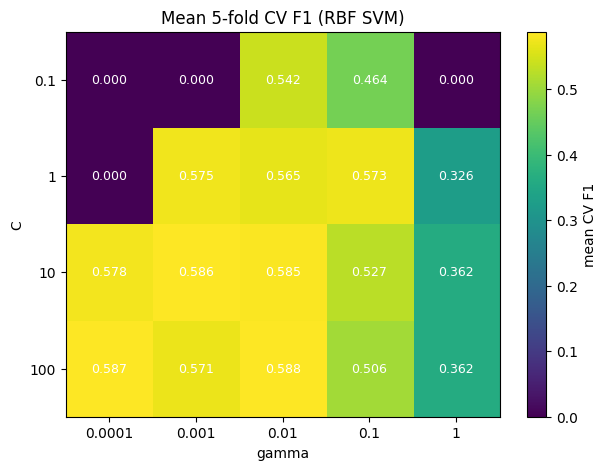

In [ ]:
scores = gs.cv_results_['mean_test_score'].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
# param_grid is expanded with keys sorted alphabetically (C outer, gamma inner) -> reshape is C x gamma
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
print(heat.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(param_grid["gamma"]))); ax.set_xticklabels(param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])));     ax.set_yticklabels(param_grid["C"])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("Mean 5-fold CV F1 (RBF SVM)")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
plt.colorbar(im, label="mean CV F1"); plt.show()

**Interpretation:** The heatmap has a wide good area (about 0.57 to 0.59) for C of 10 or more and gamma of 0.01 or less. Gamma=1 and C=0.1 with tiny gamma are bad. The best cell (C=100, gamma=0.01) is only slightly better than its neighbours.

TUNED RBF test metrics: {'Accuracy': 0.7786, 'Precision': 0.5939, 'Recall': 0.5241, 'F1': 0.5568}


Untuned RBF test metrics (Part 2): {'Accuracy': 0.7928, 'Precision': 0.6444, 'Recall': 0.4893, 'F1': 0.5562}
CV F1 = 0.5877 vs Test F1 = 0.5568 (gap 0.0309)


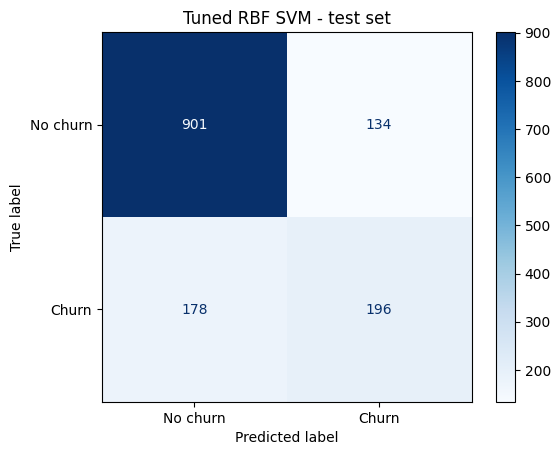

In [ ]:
best_svm = gs.best_estimator_            # already refit on the full training set
y_pred_best = best_svm.predict(X_test_s)
m_best = metrics(y_test, y_pred_best)
print("TUNED RBF test metrics:", {k: round(v, 4) for k, v in m_best.items()})
print("Untuned RBF test metrics (Part 2):", {k: round(v, 4) for k, v in metrics(y_test, models['rbf'].predict(X_test_s)).items()})
print("CV F1 = %.4f vs Test F1 = %.4f (gap %.4f)" % (gs.best_score_, m_best["F1"], gs.best_score_ - m_best["F1"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=["No churn", "Churn"], cmap="Blues")
plt.title("Tuned RBF SVM - test set"); plt.show()

**Interpretation:** The tuned model still misses about half of the churners (recall 0.524). Accuracy looks fine (0.779) only because most customers do not churn.

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

**Answer:** Best values were C=100 and gamma=0.01 with a CV F1 of 0.5877.


(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

**Answer:** Several combinations are about the same. For C of 10 or 100 and gamma from 0.0001 to 0.01 the score stays around 0.57 to 0.59. Gamma=1 is bad (about 0.33 to 0.36) and C=0.1 with small gamma gives 0. So the model is not very sensitive as long as we avoid the extremes.


(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

**Answer:** CV F1 was 0.5877 and test F1 was 0.5568, so the gap is 0.031, which is small. A big gap would mean the model is overfitting or the CV score was too optimistic.


(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

**Answer:** Not really worth it. Tuned F1 was 0.5568 and untuned F1 was 0.5562, almost the same. The grid search took about 80 s while one normal fit takes less than 1 s.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


,Accuracy,Precision,Recall,F1
class_weight=None,0.7786,0.5939,0.5241,0.5568
class_weight='balanced',0.7466,0.5152,0.7701,0.6174


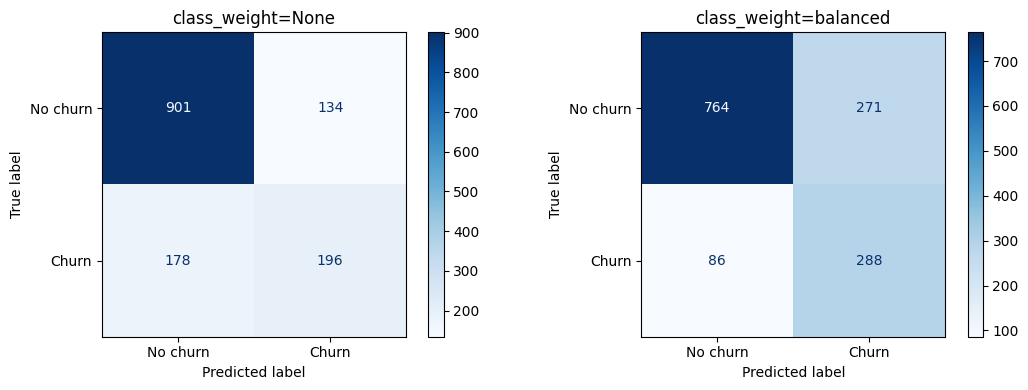

In [ ]:
bp = gs.best_params_
svm_none = SVC(kernel='rbf', C=bp["C"], gamma=bp["gamma"], class_weight=None, probability=True, random_state=42).fit(X_train_s, y_train)
svm_bal  = SVC(kernel='rbf', C=bp["C"], gamma=bp["gamma"], class_weight='balanced', probability=True, random_state=42).fit(X_train_s, y_train)

cw = {}
for name, m in [("class_weight=None", svm_none), ("class_weight='balanced'", svm_bal)]:
    cw[name] = metrics(y_test, m.predict(X_test_s))      # predict() -> decision threshold at decision_function = 0
cw_df = pd.DataFrame(cw).T.round(4)
display(cw_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, m) in zip(axes, [("None", svm_none), ("balanced", svm_bal)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test_s, y_test, display_labels=["No churn", "Churn"], cmap="Blues", ax=ax)
    ax.set_title(f"class_weight={name}")
plt.tight_layout(); plt.show()

**Interpretation:** Unweighted has TP 196, FN 178, FP 134, TN 901. Balanced has TP 288, FN 86, FP 271, TN 764. So balanced catches many more churners but also gives about twice the false alarms.

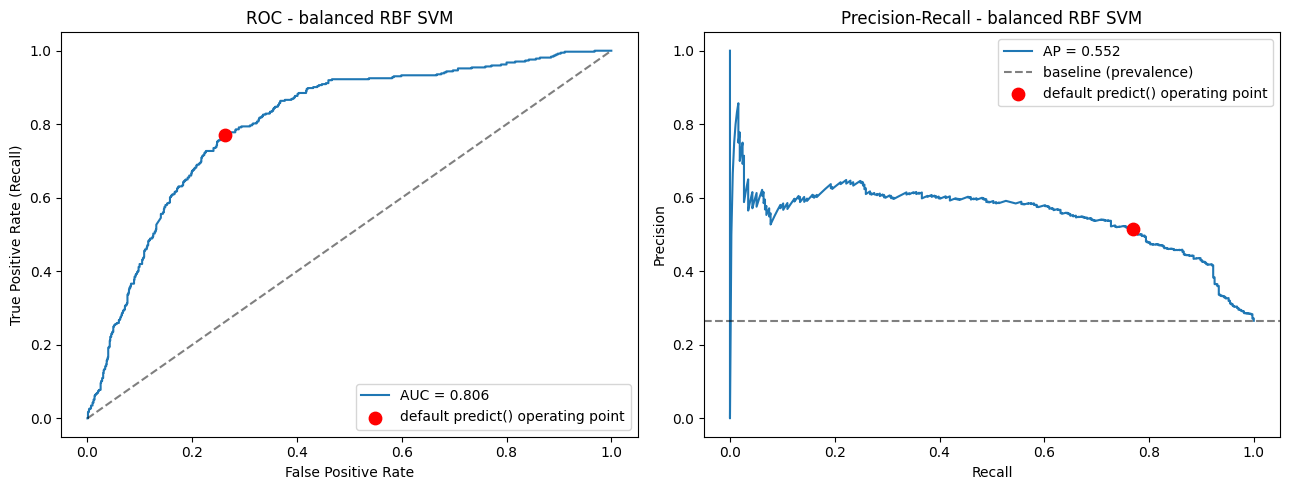

ROC-AUC = 0.8058 | Avg Precision = 0.5522 | operating point: recall=0.770 precision=0.515 FPR=0.262


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]          # needs probability=True (Platt scaling)
auc = roc_auc_score(y_test, proba_bal); ap = average_precision_score(y_test, proba_bal)
fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)

# operating point of the default predict() (decision_function > 0) on the balanced model
yp = svm_bal.predict(X_test_s)
op_fpr = ((yp == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
op_tpr = ((yp == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
op_prec, op_rec = precision_score(y_test, yp), recall_score(y_test, yp)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); axes[0].plot([0, 1], [0, 1], "k--", alpha=.5)
axes[0].scatter(op_fpr, op_tpr, c="red", s=80, zorder=5, label="default predict() operating point")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)"); axes[0].set_title("ROC - balanced RBF SVM"); axes[0].legend()
axes[1].plot(rec, prec, label=f"AP = {ap:.3f}"); axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=.5, label="baseline (prevalence)")
axes[1].scatter(op_rec, op_prec, c="red", s=80, zorder=5, label="default predict() operating point")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall - balanced RBF SVM"); axes[1].legend()
plt.tight_layout(); plt.show()
print("ROC-AUC = %.4f | Avg Precision = %.4f | operating point: recall=%.3f precision=%.3f FPR=%.3f" % (auc, ap, op_rec, op_prec, op_fpr))

**Interpretation:** ROC-AUC is 0.806 and average precision is 0.552, while a random model would get 0.265. So the model ranks churners well. The red dot is the default predict() point (recall 0.770, false positive rate 0.262).

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

**Answer:** Precision went down from 0.5939 to 0.5152 and recall went up from 0.5241 to 0.7701. F1 went from 0.5568 to 0.6174 and accuracy went down from 0.7786 to 0.7466.


(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

**Answer:** Missing a churner is more costly, because we lose the customer, while a false alarm only wastes a small offer. So I would deploy the balanced model. It catches about 92 more churners but gives about 137 more false alarms.


(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

**Answer:** I had to set probability=True in SVC(). It uses Platt scaling, which makes training slower.

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Same split as everywhere else. Tree models use unscaled data; LR/KNN/SVM use scaled data.
dt = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     {"n_estimators": [100, 300], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5]},
                     cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_

lr  = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
knn = KNeighborsClassifier(n_neighbors=11).fit(X_train_s, y_train)

results = {
    "Decision Tree":       metrics(y_test, dt.predict(X_test)),
    "Random Forest (tuned)": metrics(y_test, rf.predict(X_test)),
    "Logistic Regression": metrics(y_test, lr.predict(X_test_s)),
    "KNN (k=11)":          metrics(y_test, knn.predict(X_test_s)),
    "SVM RBF tuned (no weights)":  metrics(y_test, svm_none.predict(X_test_s)),
    "SVM RBF tuned (balanced)":    metrics(y_test, svm_bal.predict(X_test_s)),
}
print("RF best params:", rf_gs.best_params_)
compare_df = pd.DataFrame(results).T.round(4)
compare_df

RF best params: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 300}


,Accuracy,Precision,Recall,F1
Decision Tree,0.7942,0.6296,0.5455,0.5845
Random Forest (tuned),0.8034,0.6667,0.5187,0.5835
Logistic Regression,0.8070,0.6584,0.5668,0.6092
KNN (k=11),0.7743,0.5787,0.5508,0.5644
SVM RBF tuned (no weights),0.7786,0.5939,0.5241,0.5568
SVM RBF tuned (balanced),0.7466,0.5152,0.7701,0.6174


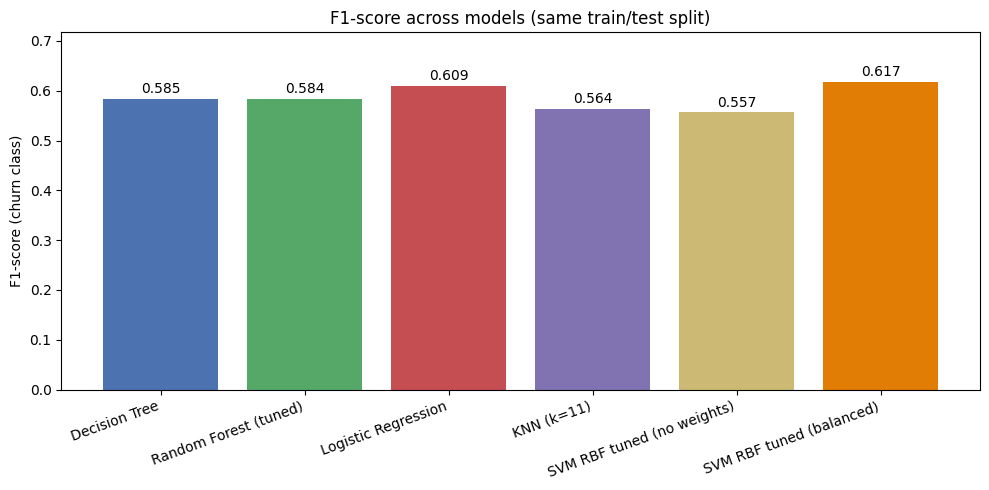

Best F1: SVM RBF tuned (balanced) | Best Recall: SVM RBF tuned (balanced)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(compare_df.index, compare_df["F1"], color=["#4c72b0", "#55a868", "#c44e52", "#8172b2", "#ccb974", "#e17c05"])
ax.bar_label(bars, fmt="%.3f", padding=2)
ax.set_ylabel("F1-score (churn class)"); ax.set_title("F1-score across models (same train/test split)")
plt.xticks(rotation=20, ha="right"); plt.ylim(0, compare_df["F1"].max() + 0.1); plt.tight_layout(); plt.show()
print("Best F1:", compare_df["F1"].idxmax(), "| Best Recall:", compare_df["Recall"].idxmax())

**Interpretation:** The balanced SVM has the highest F1 (0.617), then Logistic Regression (0.609). The others are between 0.557 and 0.585. The unweighted SVM is the lowest, so the balanced SVM wins mainly because of class weights.

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

**Answer:** Balanced SVM wins on F1 (0.6174) and also on recall (0.7701), so it is the same model for both. Logistic Regression is second on F1 (0.6092).


(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

**Answer:** Not for the normal SVM. Its F1 (0.5568) is lower than Decision Tree, Random Forest and Logistic Regression, and it is much slower. The SVM only wins because of class_weight='balanced'.


(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

**Answer:** I would recommend the balanced SVM because it has the best recall (0.7701) and best F1 (0.6174). The downside is lower precision (0.5152) and accuracy (0.7466). Logistic Regression is also a good choice because it is simpler and faster.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
final_model = svm_bal      # final chosen model: tuned RBF SVM with class_weight='balanced'
out = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_model.predict(X_test_s),
    "churn_probability": final_model.predict_proba(X_test_s)[:, 1],
    "decision_score": final_model.decision_function(X_test_s),
})
out.to_csv("svm_predictions.csv", index=False)
print(out.shape); out.head(10)

(1409, 4)


,true_label,predicted_label,churn_probability,decision_score
0,0,0,0.060593,-1.779096
1,0,1,0.604234,1.259430
2,0,0,0.040179,-2.177052
3,0,0,0.254836,-0.154549
4,0,0,0.038981,-2.206137
5,0,1,0.611928,1.288718
6,0,1,0.362082,0.318101
7,0,0,0.157781,-0.724971
8,0,0,0.058499,-1.813463
9,1,1,0.475096,0.767899


**Executive Summary**

I chose the RBF SVM with C=100 and gamma=0.01 and class_weight='balanced', trained on scaled features. On the test set it got recall 0.770, precision 0.515, F1 0.617 and accuracy 0.747, which is the best F1 and recall of the five models. The main trade-off was that balancing increased recall from 0.524 to 0.770 but decreased precision from 0.594 to 0.515. I think this is fine because losing a customer costs more than a wasted offer. Tuning itself did not help much (F1 0.5562 to 0.5568), and Logistic Regression was close with F1 0.609. One limitation is that I only used class weights for the SVM, so the comparison with other models is not completely fair. Predictions are saved in svm_predictions.csv.

**Final Reflection**
(a) What was the single most surprising result in this lab?

**Answer:** The surprising thing was that tuning did not improve the test F1 (0.5562 to 0.5568). Also class_weight='balanced' improved recall a lot, from 0.524 to 0.770.


(b) If you had one more hour, what would you try next?

**Answer:** I would try SMOTE, class weights on the other models too, and some feature engineering. I would also try changing the threshold to balance precision and recall.